# Part A: Data Preparation

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Conv2D, MaxPooling2D, Dropout
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
print(tf.__version__)

2.22.0-rc0


# Part A: Data Preparation

In [4]:
fashion_mnist.load_data()

((array([[[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         ...,
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0

In [5]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

In [6]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (60000, 28, 28)
y_train: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


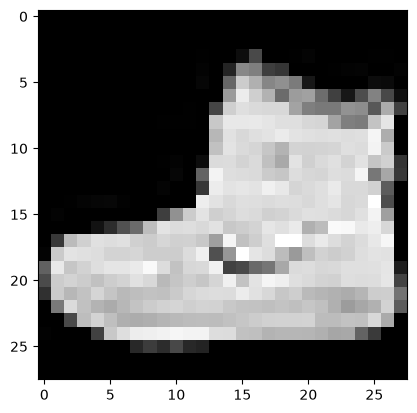

In [7]:
plt.imshow(X_train[0], cmap="gray")
plt.show()

In [8]:
print(y_train[0])

9


In [9]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

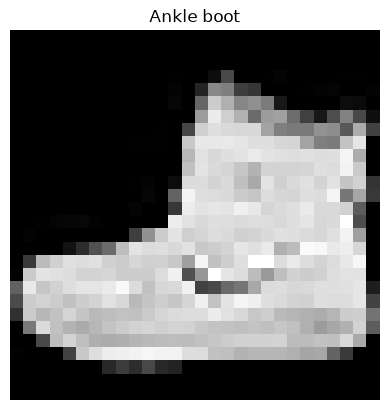

In [10]:
plt.imshow(X_train[0], cmap="gray")
plt.title(class_names[y_train[0]])
plt.axis("off")
plt.show()

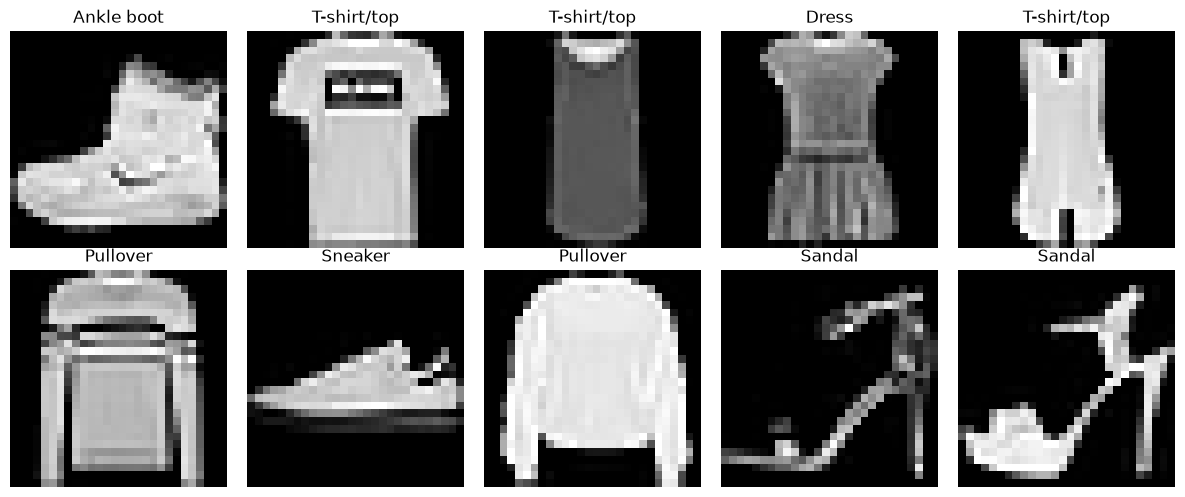

In [11]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0
Maximum pixel value: 255


In [13]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [14]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [15]:
X_val = X_train[-10000:]
y_val = y_train[-10000:]

X_train = X_train[:-10000]
y_train = y_train[:-10000]

In [16]:
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Validation images:", X_val.shape)
print("Validation labels:", y_val.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 28, 28)
Training labels: (50000,)
Validation images: (10000, 28, 28)
Validation labels: (10000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [17]:
print("Number of classes:", len(class_names))

Number of classes: 10


In [18]:
print(np.unique(y_train))

[0 1 2 3 4 5 6 7 8 9]


# Part B: Baseline Neural Network

In [19]:
dense_model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

d:\Documents\Ml project\image-classification-project\venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [20]:
dense_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
dense_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [22]:
dense_history = dense_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val)
)

Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - accuracy: 0.8155 - loss: 0.5306 - val_accuracy: 0.8418 - val_loss: 0.4624
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.8615 - loss: 0.3828 - val_accuracy: 0.8591 - val_loss: 0.3860
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8753 - loss: 0.3421 - val_accuracy: 0.8678 - val_loss: 0.3667
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8839 - loss: 0.3158 - val_accuracy: 0.8751 - val_loss: 0.3524
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8903 - loss: 0.2984 - val_accuracy: 0.8739 - val_loss: 0.3472
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8950 - loss: 0.2816 - val_accuracy: 0.8733 - val_loss: 0.3539
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9007 - loss: 0.2674 - val_accuracy: 0.8731 - val_loss: 0.3551
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9050 - loss: 0.2560 - val_accuracy

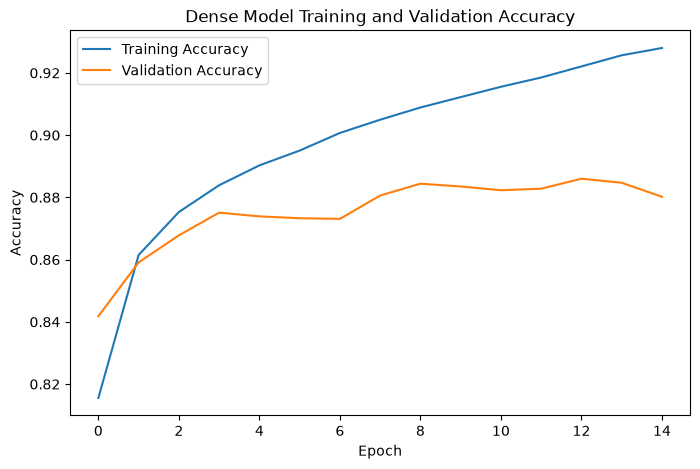

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(dense_history.history["accuracy"], label="Training Accuracy")
plt.plot(dense_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Dense Model Training and Validation Accuracy")
plt.legend()
plt.show()

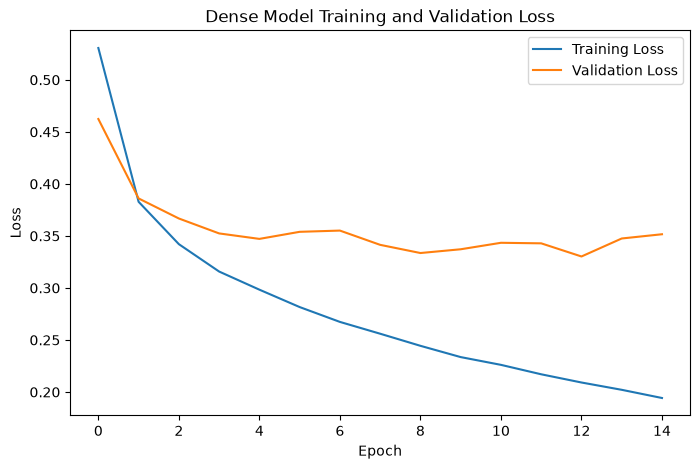

In [24]:
plt.figure(figsize=(8, 5))
plt.plot(dense_history.history["loss"], label="Training Loss")
plt.plot(dense_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Dense Model Training and Validation Loss")
plt.legend()
plt.show()

In [25]:
dense_test_loss, dense_test_accuracy = dense_model.evaluate(
    X_test,
    y_test
)

print("Dense Model Test Loss:", dense_test_loss)
print("Dense Model Test Accuracy:", dense_test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8752 - loss: 0.3816
Dense Model Test Loss: 0.38161906599998474
Dense Model Test Accuracy: 0.8751999735832214


In [26]:
print(f"Dense Model Test Accuracy: {dense_test_accuracy * 100:.2f}%")

Dense Model Test Accuracy: 87.52%


In [27]:
dense_parameters = dense_model.count_params()

print("Dense Model Parameters:", dense_parameters)

Dense Model Parameters: 109386


In [28]:
dense_predictions = dense_model.predict(X_test)
dense_predicted_labels = np.argmax(dense_predictions, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [29]:
print("Predicted Labels:", dense_predicted_labels[:10])
print("Actual Labels:", y_test[:10])

Predicted Labels: [9 2 1 1 6 1 4 6 5 7]
Actual Labels: [9 2 1 1 6 1 4 6 5 7]


In [30]:
print(
    classification_report(
        y_test,
        dense_predicted_labels,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.86      0.79      0.82      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.79      0.79      0.79      1000
       Dress       0.80      0.93      0.86      1000
        Coat       0.77      0.83      0.80      1000
      Sandal       0.98      0.95      0.97      1000
       Shirt       0.75      0.64      0.69      1000
     Sneaker       0.87      0.99      0.93      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.98      0.89      0.93      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.87     10000
weighted avg       0.88      0.88      0.87     10000



In [31]:
dense_model.save("models/dense_model.keras")

# Part C: Convolutional Neural Network

In [32]:
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_val_cnn = X_val.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

In [33]:
print("Training shape:", X_train_cnn.shape)
print("Validation shape:", X_val_cnn.shape)
print("Testing shape:", X_test_cnn.shape)

Training shape: (50000, 28, 28, 1)
Validation shape: (10000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [34]:
cnn_model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(10, activation="softmax")
])

d:\Documents\Ml project\image-classification-project\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [35]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [37]:
cnn_history = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val_cnn, y_val)
)

Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 40s 49ms/step - accuracy: 0.7852 - loss: 0.5935 - val_accuracy: 0.8600 - val_loss: 0.3858
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 38s 48ms/step - accuracy: 0.8594 - loss: 0.3945 - val_accuracy: 0.8809 - val_loss: 0.3261
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 47ms/step - accuracy: 0.8776 - loss: 0.3383 - val_accuracy: 0.8904 - val_loss: 0.3003
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 30s 38ms/step - accuracy: 0.8897 - loss: 0.3052 - val_accuracy: 0.8961 - val_loss: 0.2790
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 48s 47ms/step - accuracy: 0.8997 - loss: 0.2788 - val_accuracy: 0.9003 - val_loss: 0.2703
Epoch 6/15
586/782 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9048 - loss: 0.2626

KeyboardInterrupt: 

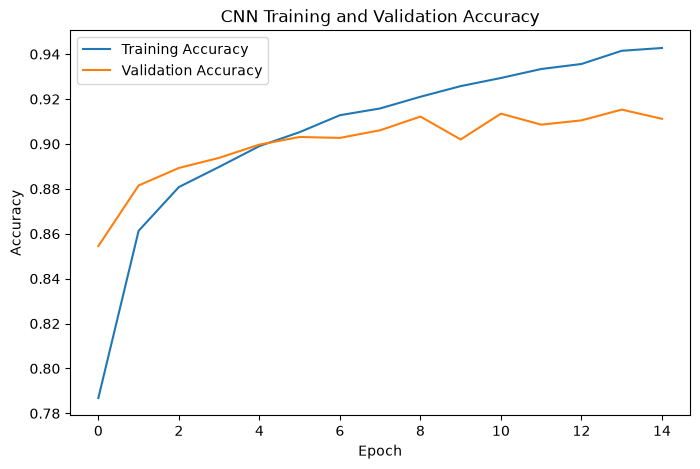

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.show()

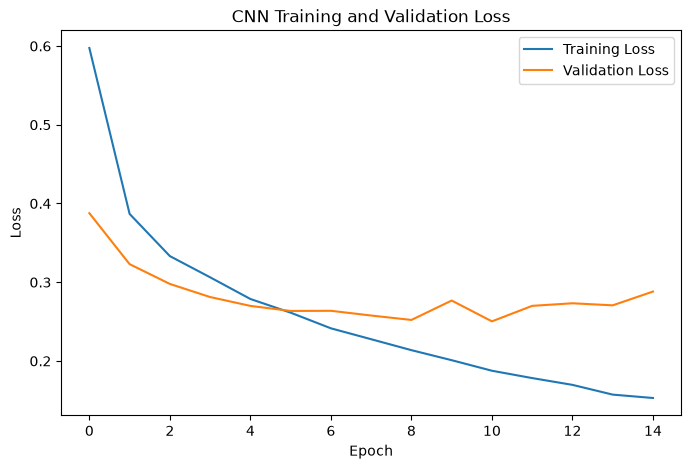

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.show()

In [ ]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test
)

print("CNN Test Loss:", cnn_test_loss)
print("CNN Test Accuracy:", cnn_test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9041 - loss: 0.3046
CNN Test Loss: 0.30457010865211487
CNN Test Accuracy: 0.9041000008583069


In [ ]:
print(f"CNN Test Accuracy: {cnn_test_accuracy * 100:.2f}%")

CNN Test Accuracy: 90.41%


In [ ]:
cnn_parameters = cnn_model.count_params()

print("CNN Model Parameters:", cnn_parameters)

CNN Model Parameters: 225034


In [ ]:
cnn_predictions = cnn_model.predict(X_test_cnn)
cnn_predicted_labels = np.argmax(cnn_predictions, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


In [ ]:
print("Predicted Labels:", cnn_predicted_labels[:10])
print("Actual Labels:", y_test[:10])

Predicted Labels: [9 2 1 1 6 1 4 6 5 7]
Actual Labels: [9 2 1 1 6 1 4 6 5 7]


In [ ]:
print(
    classification_report(
        y_test,
        cnn_predicted_labels,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.86      0.86      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.85      0.85      0.85      1000
       Dress       0.91      0.91      0.91      1000
        Coat       0.78      0.94      0.85      1000
      Sandal       0.99      0.96      0.98      1000
       Shirt       0.79      0.63      0.70      1000
     Sneaker       0.93      0.98      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



In [ ]:
cnn_model.save("models/cnn_model.keras")

# Part D: Evaluation and Comparison

In [ ]:
print(f"Dense Model Test Accuracy: {dense_test_accuracy * 100:.2f}%")
print(f"CNN Model Test Accuracy: {cnn_test_accuracy * 100:.2f}%")

Dense Model Test Accuracy: 87.43%
CNN Model Test Accuracy: 90.41%


In [ ]:
print("Dense Model Parameters:", dense_parameters)
print("CNN Model Parameters:", cnn_parameters)

Dense Model Parameters: 109386
CNN Model Parameters: 225034


In [ ]:
comparison_data = {
    "Model": ["Dense Neural Network", "CNN"],
    "Test Accuracy": [
        dense_test_accuracy * 100,
        cnn_test_accuracy * 100
    ],
    "Trainable Parameters": [
        dense_parameters,
        cnn_parameters
    ]
}

comparison_df = pd.DataFrame(comparison_data)

comparison_df

,Model,Test Accuracy,Trainable Parameters
0,Dense Neural Network,87.43,109386
1,CNN,90.41,225034


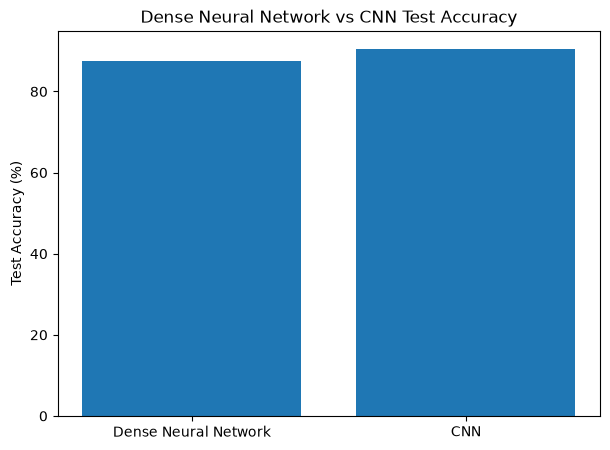

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy"]
)

plt.ylabel("Test Accuracy (%)")
plt.title("Dense Neural Network vs CNN Test Accuracy")
plt.show()

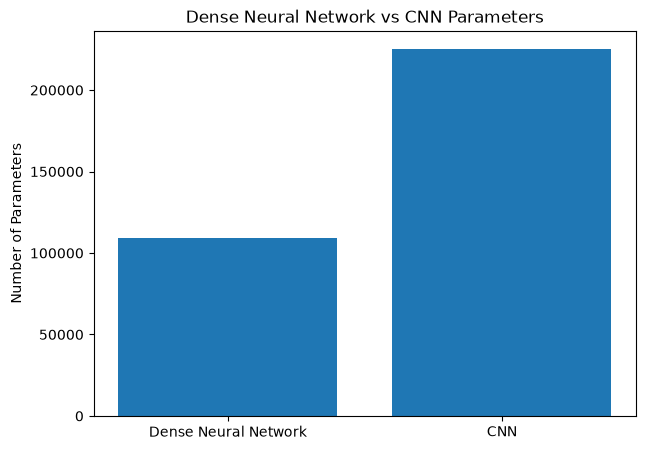

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Trainable Parameters"]
)

plt.ylabel("Number of Parameters")
plt.title("Dense Neural Network vs CNN Parameters")
plt.show()

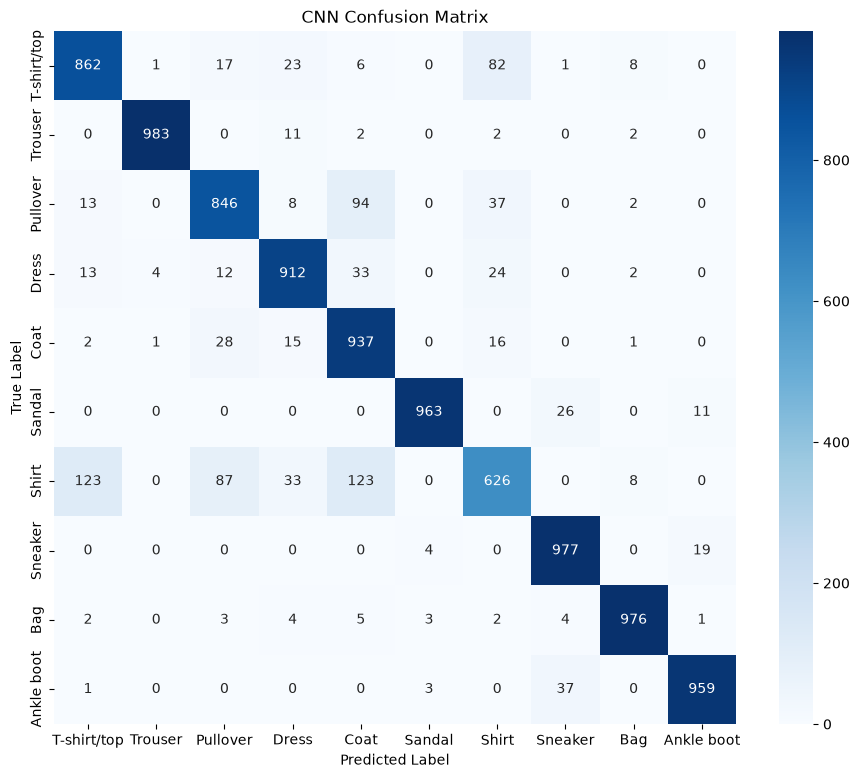

In [ ]:
cnn_confusion_matrix = confusion_matrix(
    y_test,
    cnn_predicted_labels
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    cnn_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Confusion Matrix")
plt.show()

In [ ]:
misclassified_indices = np.where(
    cnn_predicted_labels != y_test
)[0]

print("Total Misclassified Images:", len(misclassified_indices))

Total Misclassified Images: 959


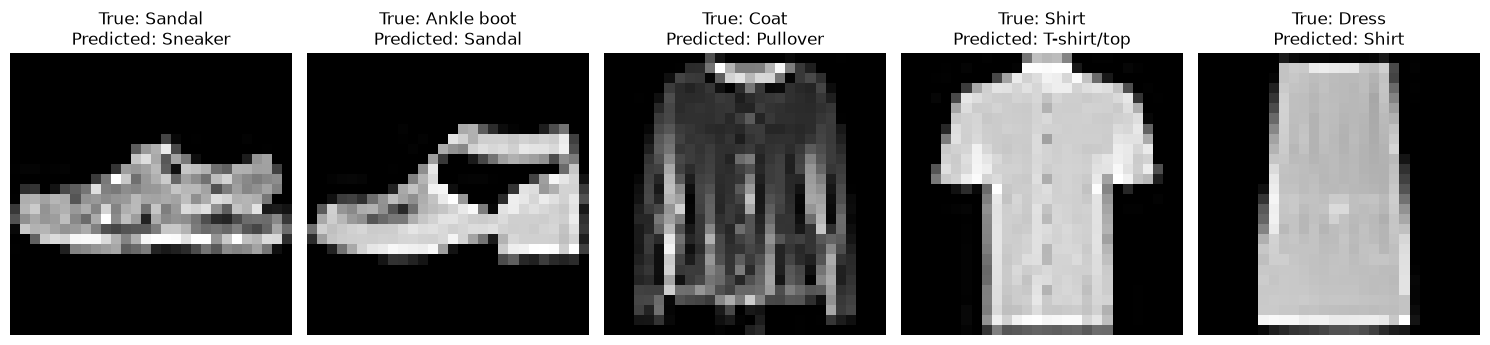

In [ ]:
plt.figure(figsize=(15, 4))

for i in range(5):
    index = misclassified_indices[i]

    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[index], cmap="gray")

    plt.title(
        f"True: {class_names[y_test[index]]}\n"
        f"Predicted: {class_names[cnn_predicted_labels[index]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    index = misclassified_indices[i]

    true_class = class_names[y_test[index]]
    predicted_class = class_names[cnn_predicted_labels[index]]
    confidence = np.max(cnn_predictions[index]) * 100

    print(
        f"Image {i + 1}: "
        f"True = {true_class}, "
        f"Predicted = {predicted_class}, "
        f"Confidence = {confidence:.2f}%"
    )

Image 1: True = Sandal, Predicted = Sneaker, Confidence = 98.05%
Image 2: True = Ankle boot, Predicted = Sandal, Confidence = 100.00%
Image 3: True = Coat, Predicted = Pullover, Confidence = 97.20%
Image 4: True = Shirt, Predicted = T-shirt/top, Confidence = 74.94%
Image 5: True = Dress, Predicted = Shirt, Confidence = 57.69%


In [ ]:
errors = []

for true_label in range(10):
    for predicted_label in range(10):
        if true_label != predicted_label:
            errors.append(
                (
                    cnn_confusion_matrix[true_label, predicted_label],
                    class_names[true_label],
                    class_names[predicted_label]
                )
            )

errors = sorted(errors, reverse=True)

for count, true_class, predicted_class in errors[:10]:
    print(
        f"{true_class} predicted as {predicted_class}: {count}"
    )

Shirt predicted as T-shirt/top: 123
Shirt predicted as Coat: 123
Pullover predicted as Coat: 94
Shirt predicted as Pullover: 87
T-shirt/top predicted as Shirt: 82
Pullover predicted as Shirt: 37
Ankle boot predicted as Sneaker: 37
Shirt predicted as Dress: 33
Dress predicted as Coat: 33
Coat predicted as Pullover: 28


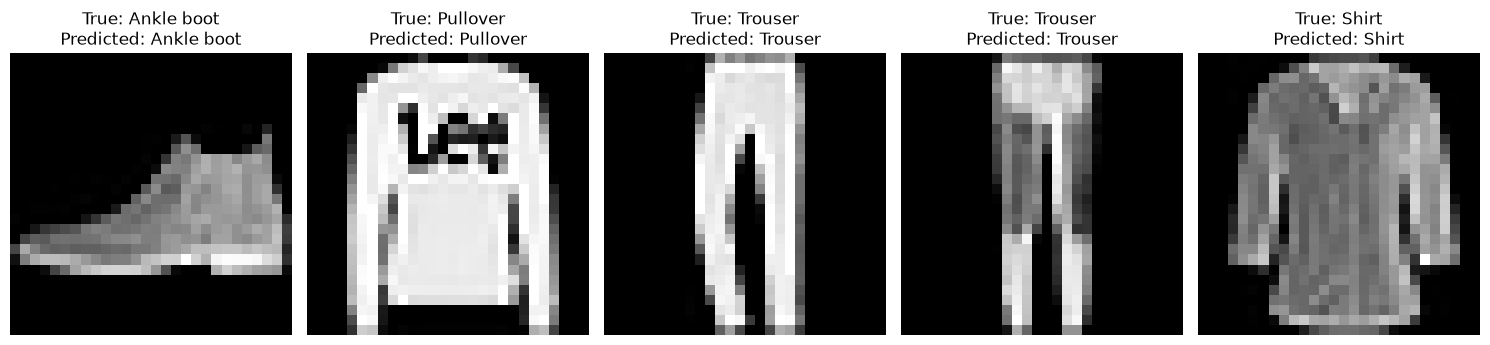

In [ ]:
correct_indices = np.where(
    cnn_predicted_labels == y_test
)[0]

plt.figure(figsize=(15, 4))

for i in range(5):
    index = correct_indices[i]

    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[index], cmap="gray")

    plt.title(
        f"True: {class_names[y_test[index]]}\n"
        f"Predicted: {class_names[cnn_predicted_labels[index]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
correct_predictions = np.sum(
    cnn_predicted_labels == y_test
)

incorrect_predictions = np.sum(
    cnn_predicted_labels != y_test
)

print("Correct Predictions:", correct_predictions)
print("Incorrect Predictions:", incorrect_predictions)
print("Total Test Images:", len(y_test))

Correct Predictions: 9041
Incorrect Predictions: 959
Total Test Images: 10000


In [ ]:
cnn_error_rate = (
    incorrect_predictions / len(y_test)
) * 100

print(f"CNN Error Rate: {cnn_error_rate:.2f}%")

CNN Error Rate: 9.59%


In [ ]:
dense_incorrect_predictions = np.sum(
    dense_predicted_labels != y_test
)

dense_error_rate = (
    dense_incorrect_predictions / len(y_test)
) * 100

print(f"Dense Model Error Rate: {dense_error_rate:.2f}%")
print(f"CNN Error Rate: {cnn_error_rate:.2f}%")

Dense Model Error Rate: 12.57%
CNN Error Rate: 9.59%


In [ ]:
final_comparison = pd.DataFrame({
    "Model": [
        "Dense Neural Network",
        "CNN"
    ],
    "Test Accuracy (%)": [
        dense_test_accuracy * 100,
        cnn_test_accuracy * 100
    ],
    "Error Rate (%)": [
        dense_error_rate,
        cnn_error_rate
    ],
    "Parameters": [
        dense_parameters,
        cnn_parameters
    ]
})

final_comparison

,Model,Test Accuracy (%),Error Rate (%),Parameters
0,Dense Neural Network,87.43,12.57,109386
1,CNN,90.41,9.59,225034


# Part E: Reflection

The CNN performed better than the fully connected neural network because CNNs are more suitable for image data. In the dense model, each 28×28 image is flattened into a single long vector before training. Because of this, the model loses some information about how nearby pixels are connected. That makes it harder for the dense network to understand shapes and patterns in the image. The CNN works differently because it looks at small parts of the image at a time and learns features such as edges, curves and simple shapes. The MaxPooling layers also reduce the size of the data while keeping the most useful information. This helped the CNN recognize the clothing images more accurately.
During training, I noticed that both models improved over time, but there was some difference between training and validation performance. The training accuracy kept increasing, while the validation accuracy improved more slowly. The training loss also became lower than the validation loss. This shows that some overfitting happened, especially after several epochs. The model was learning the training data very well, but it was not improving as much on unseen data. The Dropout layer in the CNN helped control this problem by randomly turning off some neurons during training.
The confusion matrix and misclassified images also showed that the CNN struggled more with classes that looked similar. For example, shirts, T-shirts, pullovers and coats can look very similar in Fashion-MNIST. Since the images are small, grayscale and only 28×28 pixels, some details are difficult to see clearly. Because of that, the model can sometimes confuse one clothing item with another.
To improve the model, I would try adding another convolutional layer, using Batch Normalization and testing different Dropout values. I would also experiment with the learning rate, batch size and number of epochs. Data augmentation could also help by creating slightly changed versions of the training images, such as small rotations, shifts or zooms. These changes may help the model learn better and improve its accuracy on new images.

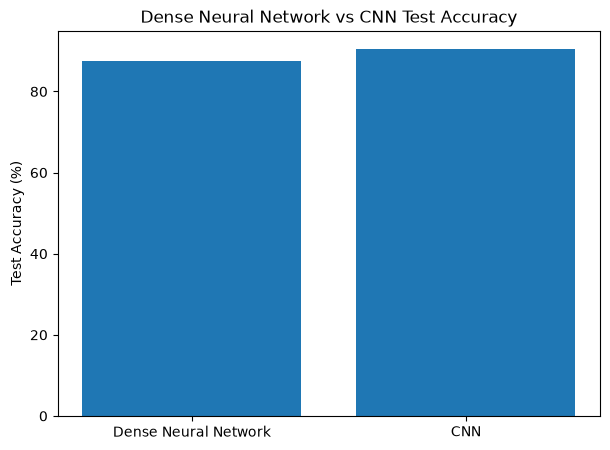

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy"]
)

plt.ylabel("Test Accuracy (%)")
plt.title("Dense Neural Network vs CNN Test Accuracy")

plt.savefig(
    "outputs/accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

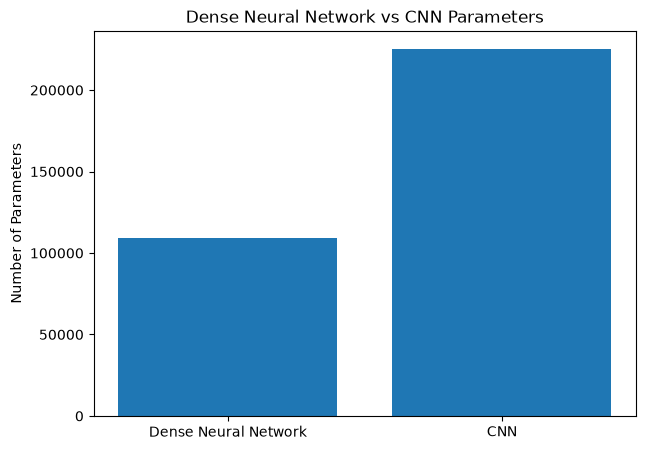

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Trainable Parameters"]
)

plt.ylabel("Number of Parameters")
plt.title("Dense Neural Network vs CNN Parameters")

plt.savefig(
    "outputs/parameter_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

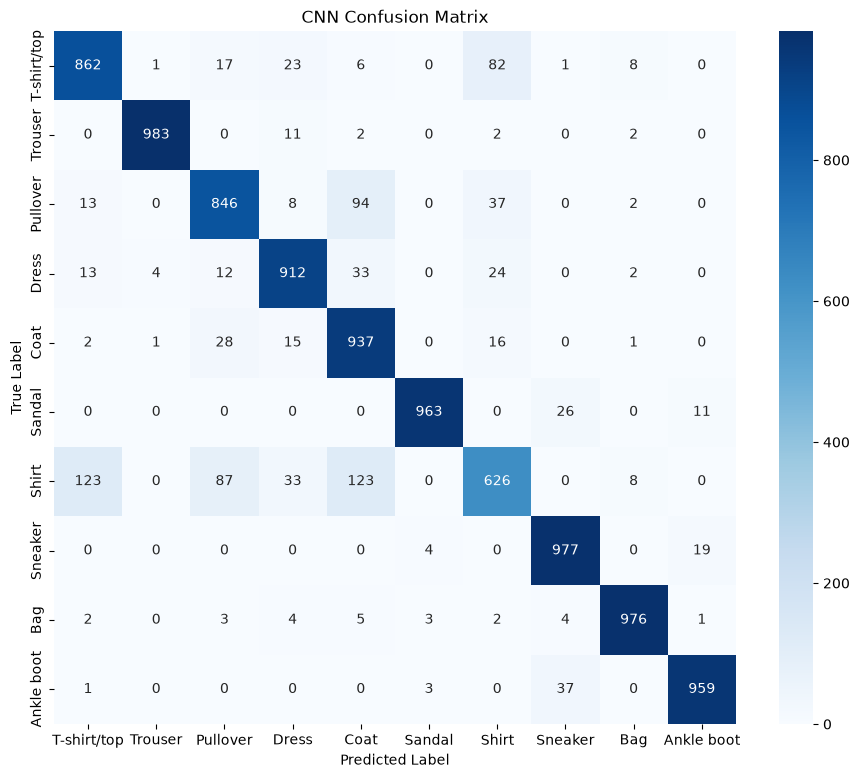

In [ ]:
plt.figure(figsize=(11, 9))

sns.heatmap(
    cnn_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Confusion Matrix")

plt.savefig(
    "outputs/cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

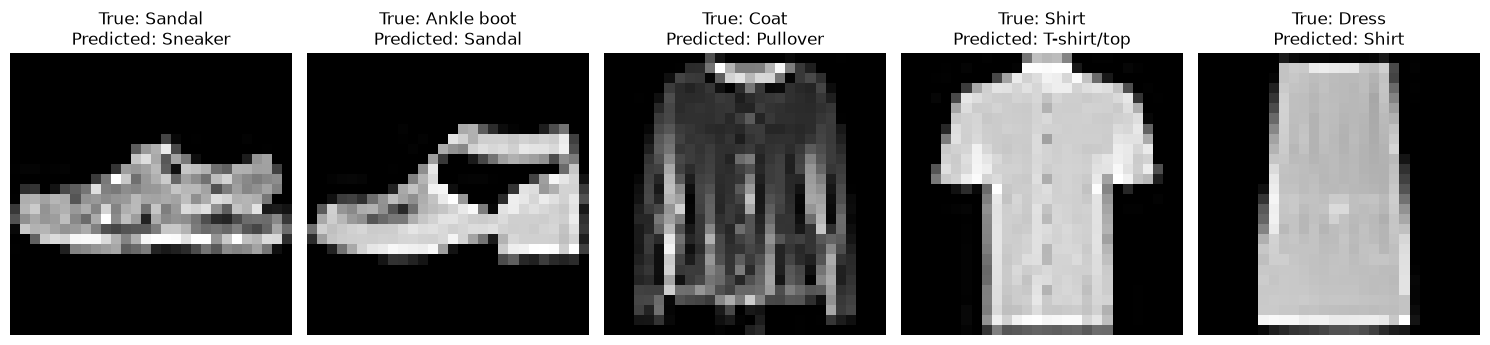

In [ ]:
plt.figure(figsize=(15, 4))

for i in range(5):
    index = misclassified_indices[i]

    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[index], cmap="gray")

    plt.title(
        f"True: {class_names[y_test[index]]}\n"
        f"Predicted: {class_names[cnn_predicted_labels[index]]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "outputs/misclassified_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

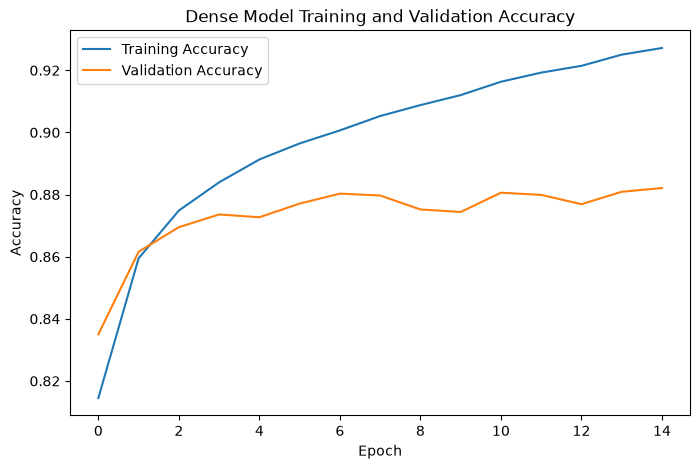

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    dense_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    dense_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Dense Model Training and Validation Accuracy")
plt.legend()

plt.savefig(
    "outputs/dense_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

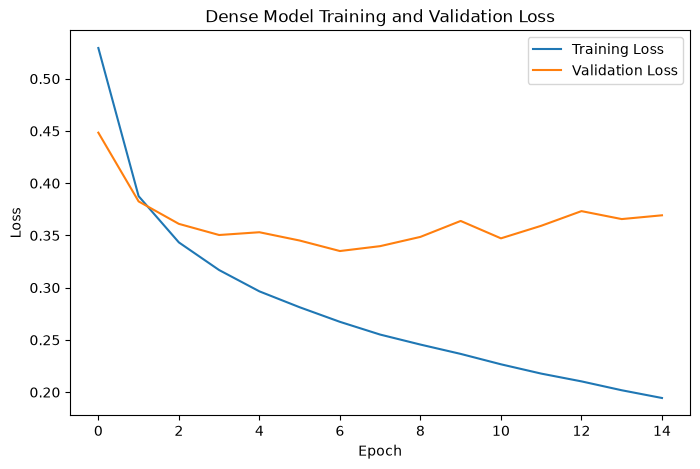

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    dense_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    dense_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Dense Model Training and Validation Loss")
plt.legend()

plt.savefig(
    "outputs/dense_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

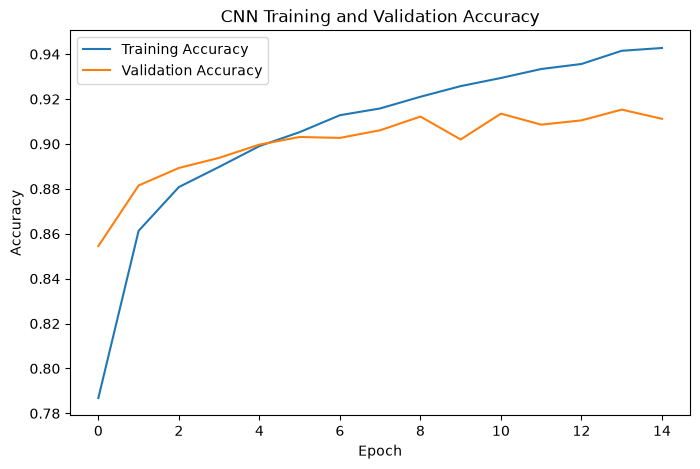

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    cnn_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    cnn_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()

plt.savefig(
    "outputs/cnn_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

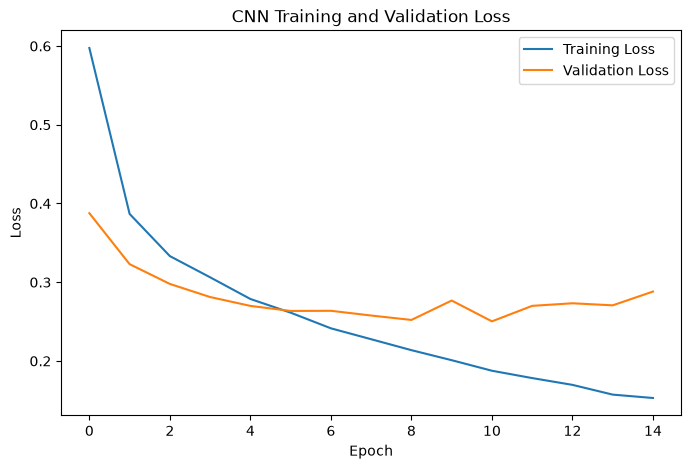

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    cnn_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    cnn_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()

plt.savefig(
    "outputs/cnn_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
final_comparison.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

In [ ]:
import os

print(os.listdir("outputs"))

['accuracy_comparison.png', 'cnn_accuracy.png', 'cnn_confusion_matrix.png', 'cnn_loss.png', 'dense_accuracy.png', 'dense_loss.png', 'misclassified_images.png', 'model_comparison.csv', 'parameter_comparison.png']


FileUpload(value=(), accept='image/*', description='Upload', multiple=True)

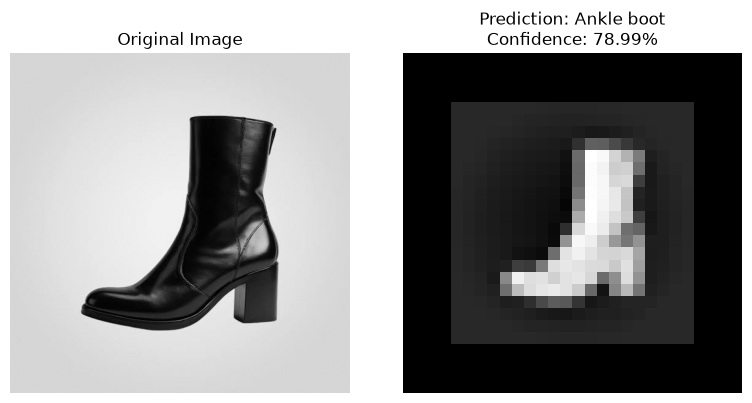

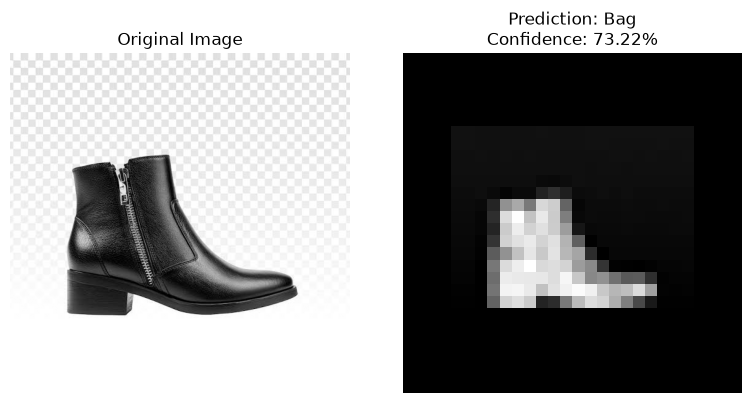

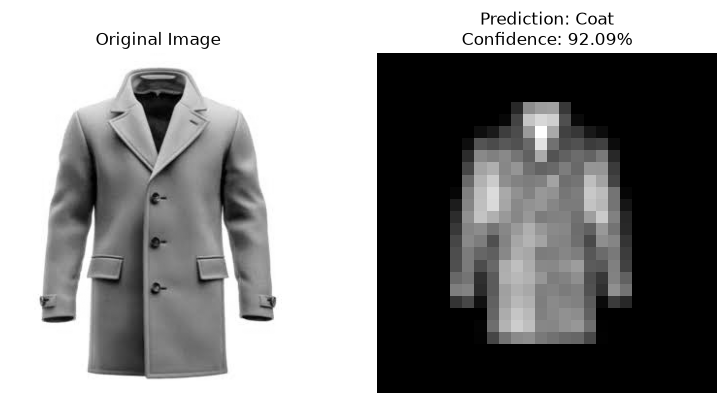

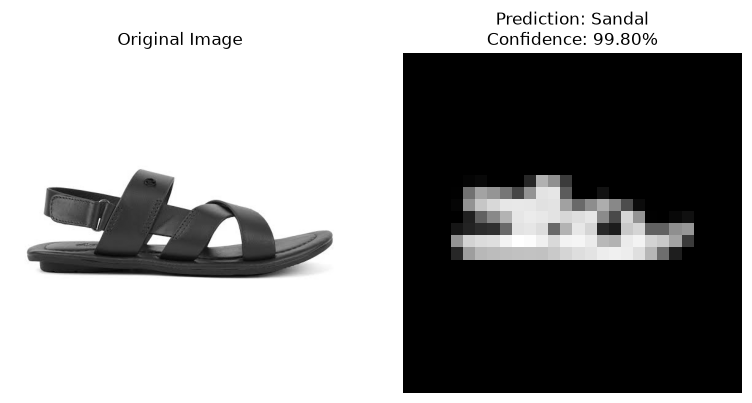

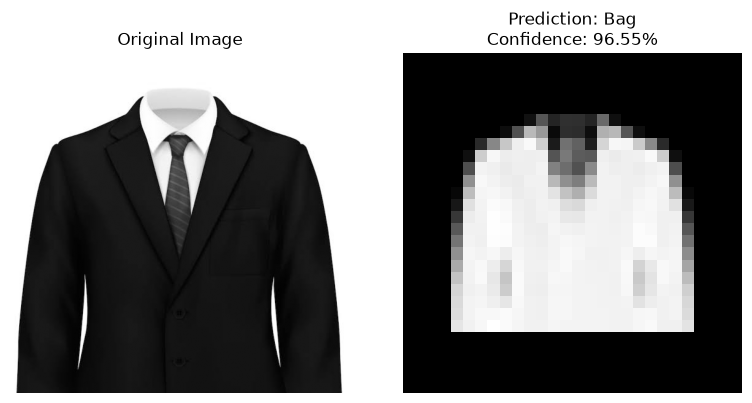

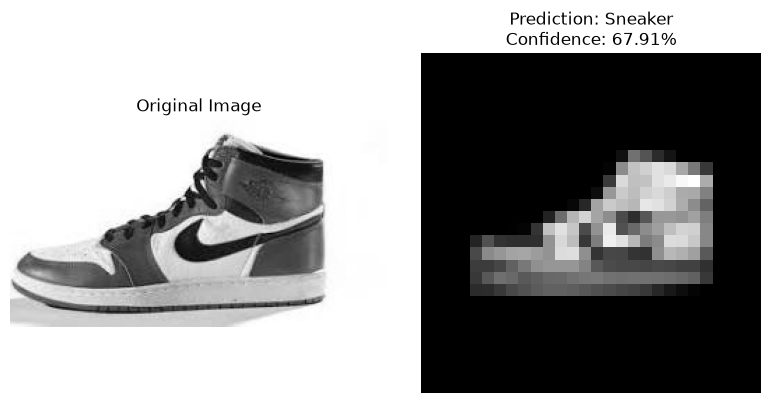

In [ ]:
from IPython.display import display
import ipywidgets as widgets
from PIL import Image, ImageOps
import io
import numpy as np
import matplotlib.pyplot as plt
import os

upload = widgets.FileUpload(
    accept="image/*",
    multiple=True
)

display(upload)

def predict_uploaded_image(change):
    if len(upload.value) == 0:
        return

    for uploaded_file in upload.value:
        original_img = Image.open(
            io.BytesIO(uploaded_file["content"])
        ).convert("L")

        img = ImageOps.invert(original_img)

        img_array = np.array(img)

        mask = img_array > 30

        if np.any(mask):
            rows = np.any(mask, axis=1)
            cols = np.any(mask, axis=0)

            top, bottom = np.where(rows)[0][[0, -1]]
            left, right = np.where(cols)[0][[0, -1]]

            img = img.crop(
                (left, top, right + 1, bottom + 1)
            )

        img.thumbnail((20, 20))

        processed_img = Image.new(
            "L",
            (28, 28),
            0
        )

        x = (28 - img.width) // 2
        y = (28 - img.height) // 2

        processed_img.paste(
            img,
            (x, y)
        )

        img_array = np.array(
            processed_img
        ).astype("float32") / 255.0

        model_input = img_array.reshape(
            1,
            28,
            28,
            1
        )

        prediction = cnn_model.predict(
            model_input,
            verbose=0
        )[0]

        predicted_class = np.argmax(prediction)
        confidence = prediction[predicted_class] * 100

        plt.figure(figsize=(8, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(original_img, cmap="gray")
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(img_array, cmap="gray")
        plt.title(
            f"Prediction: {class_names[predicted_class]}\n"
            f"Confidence: {confidence:.2f}%"
        )
        plt.axis("off")

        plt.tight_layout()

        os.makedirs("outputs", exist_ok=True)

        existing_files = [
            f for f in os.listdir("outputs")
            if f.startswith("uploaded_prediction_")
            and f.endswith(".png")
        ]

        prediction_number = len(existing_files) + 1

        save_path = (
            f"outputs/uploaded_prediction_"
            f"{prediction_number}.png"
        )

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        print("Predicted Class:", class_names[predicted_class])
        print(f"Confidence: {confidence:.2f}%")
        print("Saved to:", save_path)
        print()

upload.observe(
    predict_uploaded_image,
    names="value"
)